# Árbol de Decisión optimizado — entrenamiento balanceado 50/50

Este experimento aplica `RandomUnderSampler` **únicamente a TRAIN** para igualar las clases 0 y 1. VALIDATION y TEST permanecen sin balancear. La búsqueda de hiperparámetros y del umbral se realiza con VALIDATION; TEST se reserva para la evaluación final.


# Árbol de Decisión — Licitaciones

Modelo para predecir `Seleccionada`. El umbral se selecciona con VALIDATION y el rendimiento final se reporta una sola vez sobre TEST.


In [19]:
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay
)
import joblib


## 1. Funciones


In [20]:
def calcula_metricas(nombre, y_true, y_pred, y_proba):
    return pd.DataFrame({
        "Modelo": [nombre],
        "Exactitud": [accuracy_score(y_true, y_pred)],
        "Precisión": [precision_score(y_true, y_pred, zero_division=0)],
        "Sensibilidad": [recall_score(y_true, y_pred, zero_division=0)],
        "F1": [f1_score(y_true, y_pred, zero_division=0)],
        "AUC": [roc_auc_score(y_true, y_proba)],
        "Average Precision": [average_precision_score(y_true, y_proba)]
    })


def mostrar_matriz(y_true, y_pred, titulo):
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred,
        labels=[0, 1],
        display_labels=["No seleccionada", "Seleccionada"],
        values_format=",d"
    )
    plt.title(titulo)
    plt.show()


def importancia_variables(modelo, columnas):
    imp = pd.Series(modelo.feature_importances_, index=columnas)
    imp.sort_values().tail(20).plot(kind="barh", figsize=(9, 7))
    plt.title("20 variables con mayor importancia")
    plt.xlabel("Importancia")
    plt.tight_layout()
    plt.show()


## 2. Carga de datos


In [21]:
ruta_datos = "LICIT_depurando_sinNulos.feather"
data = pd.read_feather(ruta_datos)

# 2. Seleccionar las columnas necesarias
columnas = [
    "Valor Total Ofertado",
    "MesPublicacion",
    "CodigoProductoONU",
    "CantidadReclamos",
    "DuracionProceso",
    "DiaSemanaPublicacion",
    "Cantidad",
    "NumeroOferentes",
    "Seleccionada"
]

data = data[columnas].copy()

# 3. Agrupar NumeroOferentes
condiciones = [
    data["NumeroOferentes"].between(1, 3),
    data["NumeroOferentes"].between(4, 6),
    data["NumeroOferentes"] == 7,
    data["NumeroOferentes"] >= 8
]

grupos = [1, 2, 3, 4]

data["GrupoOferentes"] = np.select(
    condiciones,
    grupos,
    default=0
).astype("int8")

# 4. Eliminar NumeroOferentes original
data.drop(columns=["NumeroOferentes"], inplace=True)

# 5. Revisar resultado
print("Dimensiones:", data.shape)
print("\nTipos de datos:")
print(data.dtypes)

print("\nDistribución de grupos:")
print(data["GrupoOferentes"].value_counts().sort_index())


TARGET = "Seleccionada"

print("Dimensiones:", data.shape)
print("\nNaN totales:", int(data.isna().sum().sum()))
print("\nDistribución de Seleccionada:")
print(data[TARGET].value_counts())
print(data[TARGET].value_counts(normalize=True).mul(100).round(2))


Dimensiones: (2248494, 9)

Tipos de datos:
Valor Total Ofertado    float64
MesPublicacion             int8
CodigoProductoONU         int32
CantidadReclamos          int16
DuracionProceso           int16
DiaSemanaPublicacion       int8
Cantidad                float64
Seleccionada               int8
GrupoOferentes             int8
dtype: object

Distribución de grupos:
GrupoOferentes
0       9289
1     346259
2     458174
3     135897
4    1298875
Name: count, dtype: int64
Dimensiones: (2248494, 9)

NaN totales: 0

Distribución de Seleccionada:
Seleccionada
0    1891337
1     357157
Name: count, dtype: int64
Seleccionada
0    84.12
1    15.88
Name: proportion, dtype: float64


## 3. Separar predictores y objetivo

No se eliminan columnas predictoras adicionales.


In [22]:
y = data[TARGET]
idx_target = data.columns.get_loc(TARGET)

if idx_target == len(data.columns) - 1:
    X = data.iloc[:, :-1]
else:
    columnas_X = [c for c in data.columns if c != TARGET]
    X = data.loc[:, columnas_X]

cols = X.columns.tolist()

print("X:", X.shape)
print("y:", y.shape)
print("Clases:", Counter(y))


X: (2248494, 8)
y: (2248494,)
Clases: Counter({0: 1891337, 1: 357157})


## 4. División TRAIN / VALIDATION / TEST

Se usa 64% TRAIN, 16% VALIDATION y 20% TEST. El árbol se entrena solo con TRAIN. VALIDATION se usa para escoger el umbral. TEST queda reservado para la evaluación final.


In [23]:
# 80% desarrollo + 20% test final
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Del 80% de desarrollo: 80% train y 20% validation
# Resultado global: 64% train, 16% validation, 20% test
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.20,
    random_state=42,
    stratify=y_dev
)

# Ya no necesitamos estas referencias
del X_dev, y_dev

print("Train     :", X_train.shape, Counter(y_train))
print("Validation:", X_val.shape, Counter(y_val))
print("Test      :", X_test.shape, Counter(y_test))


Train     : (1439036, 8) Counter({0: 1210455, 1: 228581})
Validation: (359759, 8) Counter({0: 302614, 1: 57145})
Test      : (449699, 8) Counter({0: 378268, 1: 71431})


## 5. Búsqueda de hiperparámetros

La búsqueda se realiza **solo con TRAIN y VALIDATION**. TEST no participa en la selección. Para cada configuración se busca además el umbral que maximiza F1 en VALIDATION.

Se usa una búsqueda aleatoria reproducible de 30 configuraciones para controlar tiempo y memoria con más de 2 millones de filas.


In [24]:
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import precision_recall_curve
import gc

# Espacio de búsqueda. No se usa GridSearchCV para evitar múltiples copias
# del dataset y reducir el riesgo de MemoryError.
param_distributions = {
    "criterion": ["gini", "entropy", "log_loss"],
    "max_depth": [6, 8, 10, 12, 15, 20, 25, None],
    "min_samples_split": [2, 20, 50, 100, 250, 500],
    "min_samples_leaf": [1, 10, 25, 50, 100, 250, 500],
    "max_features": [None, "sqrt", "log2"],
    "ccp_alpha": [0.0, 1e-7, 1e-6, 1e-5]
}

N_CANDIDATOS = 30

candidatos = list(ParameterSampler(
    param_distributions,
    n_iter=N_CANDIDATOS,
    random_state=42
))

# Incluir explícitamente el árbol que ya veníamos usando como referencia.
referencia = {
    "criterion": "entropy",
    "max_depth": 10,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "max_features": None,
    "ccp_alpha": 0.0
}

if referencia not in candidatos:
    candidatos.append(referencia)

print(f"Configuraciones a evaluar: {len(candidatos)}")


Configuraciones a evaluar: 31


### Función para encontrar el mejor umbral

`precision_recall_curve` permite evaluar todos los puntos de corte generados por las probabilidades del modelo sin recorrer manualmente una grilla de umbrales.


In [25]:
def mejor_umbral_f1(y_true, y_proba):
    precision, recall, thresholds = precision_recall_curve(y_true, y_proba)

    # precision y recall tienen un elemento más que thresholds.
    precision_t = precision[:-1]
    recall_t = recall[:-1]

    denominador = precision_t + recall_t
    f1 = np.divide(
        2 * precision_t * recall_t,
        denominador,
        out=np.zeros_like(denominador, dtype=float),
        where=denominador != 0
    )

    idx = int(np.nanargmax(f1))

    return {
        "umbral": float(thresholds[idx]),
        "f1": float(f1[idx]),
        "precision": float(precision_t[idx]),
        "recall": float(recall_t[idx])
    }


### Ejecutar búsqueda

Los modelos se entrenan **uno por uno** (`n_jobs` no aplica a un árbol individual), y cada modelo temporal se libera antes de continuar para limitar el uso de RAM.


In [26]:
# ============================================================
# BALANCEO 50/50 SOLO DEL CONJUNTO TRAIN
# VALIDATION y TEST conservan su distribución original
# ============================================================
from imblearn.under_sampling import RandomUnderSampler

print("DISTRIBUCIÓN TRAIN ANTES DEL BALANCEO")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True).round(4))

rus = RandomUnderSampler(
    sampling_strategy=1.0,
    random_state=42
)

X_train_bal, y_train_bal = rus.fit_resample(
    X_train,
    y_train
)

print("\nDISTRIBUCIÓN TRAIN DESPUÉS DEL BALANCEO")
print(y_train_bal.value_counts())
print(y_train_bal.value_counts(normalize=True).round(4))

print("\nTamaño TRAIN original:", X_train.shape)
print("Tamaño TRAIN balanceado:", X_train_bal.shape)


DISTRIBUCIÓN TRAIN ANTES DEL BALANCEO
Seleccionada
0    1210455
1     228581
Name: count, dtype: int64
Seleccionada
0    0.8412
1    0.1588
Name: proportion, dtype: float64

DISTRIBUCIÓN TRAIN DESPUÉS DEL BALANCEO
Seleccionada
0    228581
1    228581
Name: count, dtype: int64
Seleccionada
0    0.5
1    0.5
Name: proportion, dtype: float64

Tamaño TRAIN original: (1439036, 8)
Tamaño TRAIN balanceado: (457162, 8)


In [27]:
resultados_busqueda = []

for i, params in enumerate(candidatos, start=1):
    print(f"[{i:02d}/{len(candidatos)}] {params}")

    candidato = DecisionTreeClassifier(
        **params,
        class_weight=None,
        random_state=42
    )

    candidato.fit(X_train_bal, y_train_bal)
    proba_val = candidato.predict_proba(X_val)[:, 1]

    opt = mejor_umbral_f1(y_val, proba_val)

    resultados_busqueda.append({
        **params,
        "Umbral": opt["umbral"],
        "Precisión_val": opt["precision"],
        "Sensibilidad_val": opt["recall"],
        "F1_val": opt["f1"],
        "AUC_val": roc_auc_score(y_val, proba_val),
        "AP_val": average_precision_score(y_val, proba_val),
        "Nodos": candidato.tree_.node_count,
        "Profundidad_real": candidato.tree_.max_depth
    })

    del candidato, proba_val
    gc.collect()

resultados_hp = (
    pd.DataFrame(resultados_busqueda)
      .sort_values(["F1_val", "AUC_val"], ascending=False)
      .reset_index(drop=True)
)

display(resultados_hp.head(15).round(5))


[01/31] {'min_samples_split': 250, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 8, 'criterion': 'entropy', 'ccp_alpha': 1e-06}
[02/31] {'min_samples_split': 50, 'min_samples_leaf': 50, 'max_features': 'log2', 'max_depth': 25, 'criterion': 'gini', 'ccp_alpha': 0.0}
[03/31] {'min_samples_split': 50, 'min_samples_leaf': 25, 'max_features': 'log2', 'max_depth': 10, 'criterion': 'log_loss', 'ccp_alpha': 1e-07}
[04/31] {'min_samples_split': 20, 'min_samples_leaf': 100, 'max_features': None, 'max_depth': 8, 'criterion': 'log_loss', 'ccp_alpha': 1e-07}
[05/31] {'min_samples_split': 2, 'min_samples_leaf': 500, 'max_features': 'log2', 'max_depth': 25, 'criterion': 'log_loss', 'ccp_alpha': 1e-05}
[06/31] {'min_samples_split': 250, 'min_samples_leaf': 100, 'max_features': 'sqrt', 'max_depth': 8, 'criterion': 'log_loss', 'ccp_alpha': 1e-05}
[07/31] {'min_samples_split': 250, 'min_samples_leaf': 50, 'max_features': 'sqrt', 'max_depth': 20, 'criterion': 'log_loss', 'ccp_alpha': 1e-07}


,min_samples_split,min_samples_leaf,max_features,max_depth,criterion,ccp_alpha,Umbral,Precisión_val,Sensibilidad_val,F1_val,AUC_val,AP_val,Nodos,Profundidad_real
0,20,50,None,15.0,entropy,0.00000,0.56604,0.31501,0.57146,0.40614,0.74743,0.36211,5645,15
1,20,50,None,NaN,gini,0.00000,0.59302,0.31618,0.56374,0.40513,0.74776,0.36219,12465,37
2,50,50,log2,25.0,gini,0.00000,0.60000,0.32301,0.54253,0.40493,0.74554,0.36258,12571,25
3,50,25,log2,15.0,log_loss,0.00000,0.58824,0.32799,0.52232,0.40295,0.74433,0.35790,7763,15
4,250,250,None,15.0,log_loss,0.00000,0.57600,0.32133,0.53975,0.40283,0.74253,0.35386,2229,15
5,250,25,None,12.0,entropy,0.00000,0.56832,0.31856,0.54386,0.40178,0.74059,0.35519,1571,12
6,250,50,sqrt,20.0,log_loss,0.00000,0.57746,0.31729,0.53950,0.39958,0.73523,0.34914,5601,20
7,50,1,sqrt,15.0,log_loss,0.00001,0.57554,0.32349,0.51999,0.39885,0.73503,0.34473,3159,15
8,20,25,None,25.0,gini,0.00000,0.58140,0.30381,0.57660,0.39794,0.74231,0.34946,24607,25
9,100,500,None,12.0,log_loss,0.00000,0.55644,0.31074,0.55153,0.39752,0.73481,0.34610,949,12


## 6. Selección del mejor modelo

La configuración ganadora se elige por **F1 en VALIDATION**. El umbral también queda fijado usando VALIDATION.


In [28]:
mejor_fila = resultados_hp.iloc[0]

mejores_params = {
    "criterion": mejor_fila["criterion"],
    "max_depth": None if pd.isna(mejor_fila["max_depth"]) else int(mejor_fila["max_depth"]),
    "min_samples_split": int(mejor_fila["min_samples_split"]),
    "min_samples_leaf": int(mejor_fila["min_samples_leaf"]),
    "max_features": mejor_fila["max_features"],
    "ccp_alpha": float(mejor_fila["ccp_alpha"])
}

# Pandas puede representar None como NaN en columnas object/mixtas.
if pd.isna(mejores_params["max_features"]):
    mejores_params["max_features"] = None

mejor_umbral = float(mejor_fila["Umbral"])

print("MEJOR CONFIGURACIÓN SEGÚN F1 EN VALIDATION")
print("=" * 55)
print(mejores_params)
print(f"Umbral:       {mejor_umbral:.6f}")
print(f"Precisión:    {mejor_fila['Precisión_val']:.4f}")
print(f"Sensibilidad: {mejor_fila['Sensibilidad_val']:.4f}")
print(f"F1:           {mejor_fila['F1_val']:.4f}")
print(f"AUC:          {mejor_fila['AUC_val']:.4f}")
print(f"Avg Precision:{mejor_fila['AP_val']:.4f}")


MEJOR CONFIGURACIÓN SEGÚN F1 EN VALIDATION
{'criterion': 'entropy', 'max_depth': 15, 'min_samples_split': 20, 'min_samples_leaf': 50, 'max_features': None, 'ccp_alpha': 1e-07}
Umbral:       0.566038
Precisión:    0.3150
Sensibilidad: 0.5715
F1:           0.4061
AUC:          0.7474
Avg Precision:0.3621


## 7. Entrenar el árbol seleccionado

Se vuelve a entrenar con TRAIN usando exactamente los hiperparámetros elegidos. VALIDATION ya no se usa después de este punto.


In [29]:
tree_clf = DecisionTreeClassifier(
    **mejores_params,
    class_weight=None,
    random_state=42
)

tree_clf.fit(X_train_bal, y_train_bal)
print("Árbol final entrenado con los hiperparámetros seleccionados.")


Árbol final entrenado con los hiperparámetros seleccionados.


## 8. Evaluación FINAL sobre TEST

TEST se utiliza una sola vez después de fijar hiperparámetros y umbral.


In [30]:
y_proba_test = tree_clf.predict_proba(X_test)[:, 1]
y_pred_test = (y_proba_test >= mejor_umbral).astype(np.int8)

metricas_test = calcula_metricas(
    "Árbol de Decisión optimizado",
    y_test,
    y_pred_test,
    y_proba_test
)

print("EVALUACIÓN FINAL - TEST")
print(f"Umbral fijado en VALIDATION: {mejor_umbral:.6f}")
display(metricas_test.round(6))


EVALUACIÓN FINAL - TEST
Umbral fijado en VALIDATION: 0.566038


,Modelo,Exactitud,Precisión,Sensibilidad,F1,AUC,Average Precision
0,Árbol de Decisión optimizado,0.735461,0.316274,0.572749,0.407516,0.748014,0.365977


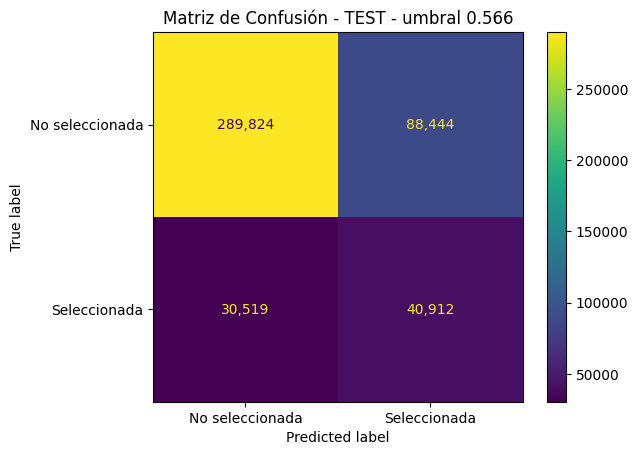

In [31]:
mostrar_matriz(
    y_test,
    y_pred_test,
    f"Matriz de Confusión - TEST - umbral {mejor_umbral:.3f}"
)


## 9. Comparación visual de los mejores candidatos


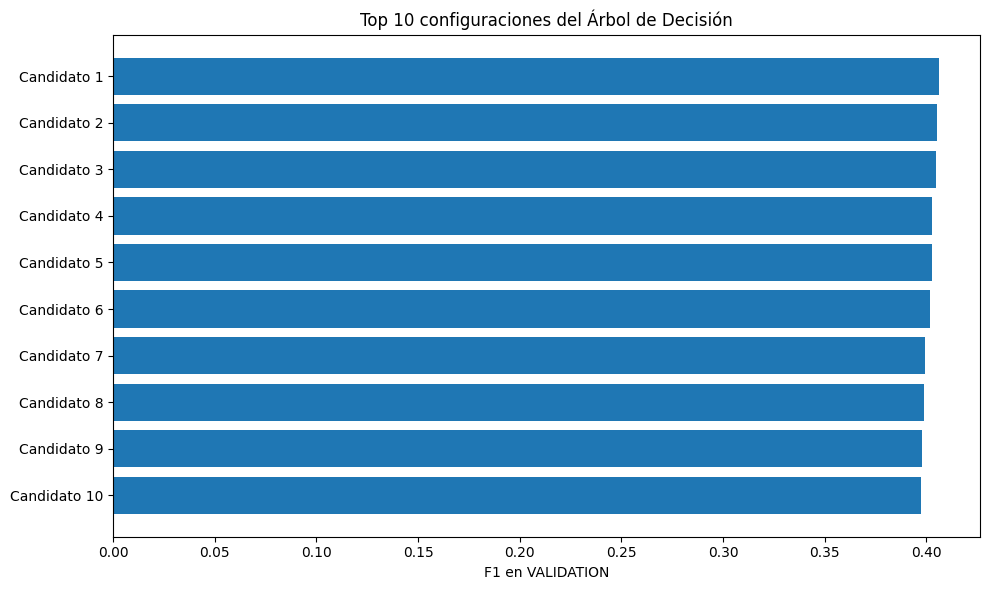

In [32]:
top = resultados_hp.head(10).copy()
top["Modelo"] = [f"Candidato {i+1}" for i in range(len(top))]

plt.figure(figsize=(10, 6))
plt.barh(top["Modelo"][::-1], top["F1_val"][::-1])
plt.xlabel("F1 en VALIDATION")
plt.title("Top 10 configuraciones del Árbol de Decisión")
plt.tight_layout()
plt.show()


## 10. Importancia de variables


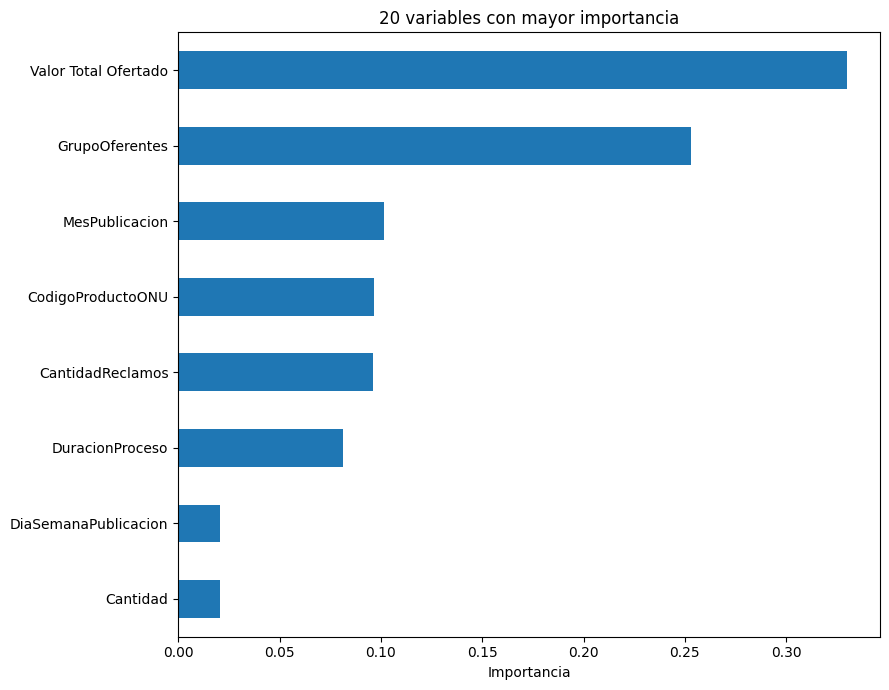

In [33]:
importancia_variables(tree_clf, cols)


## 11. Visualización parcial del árbol


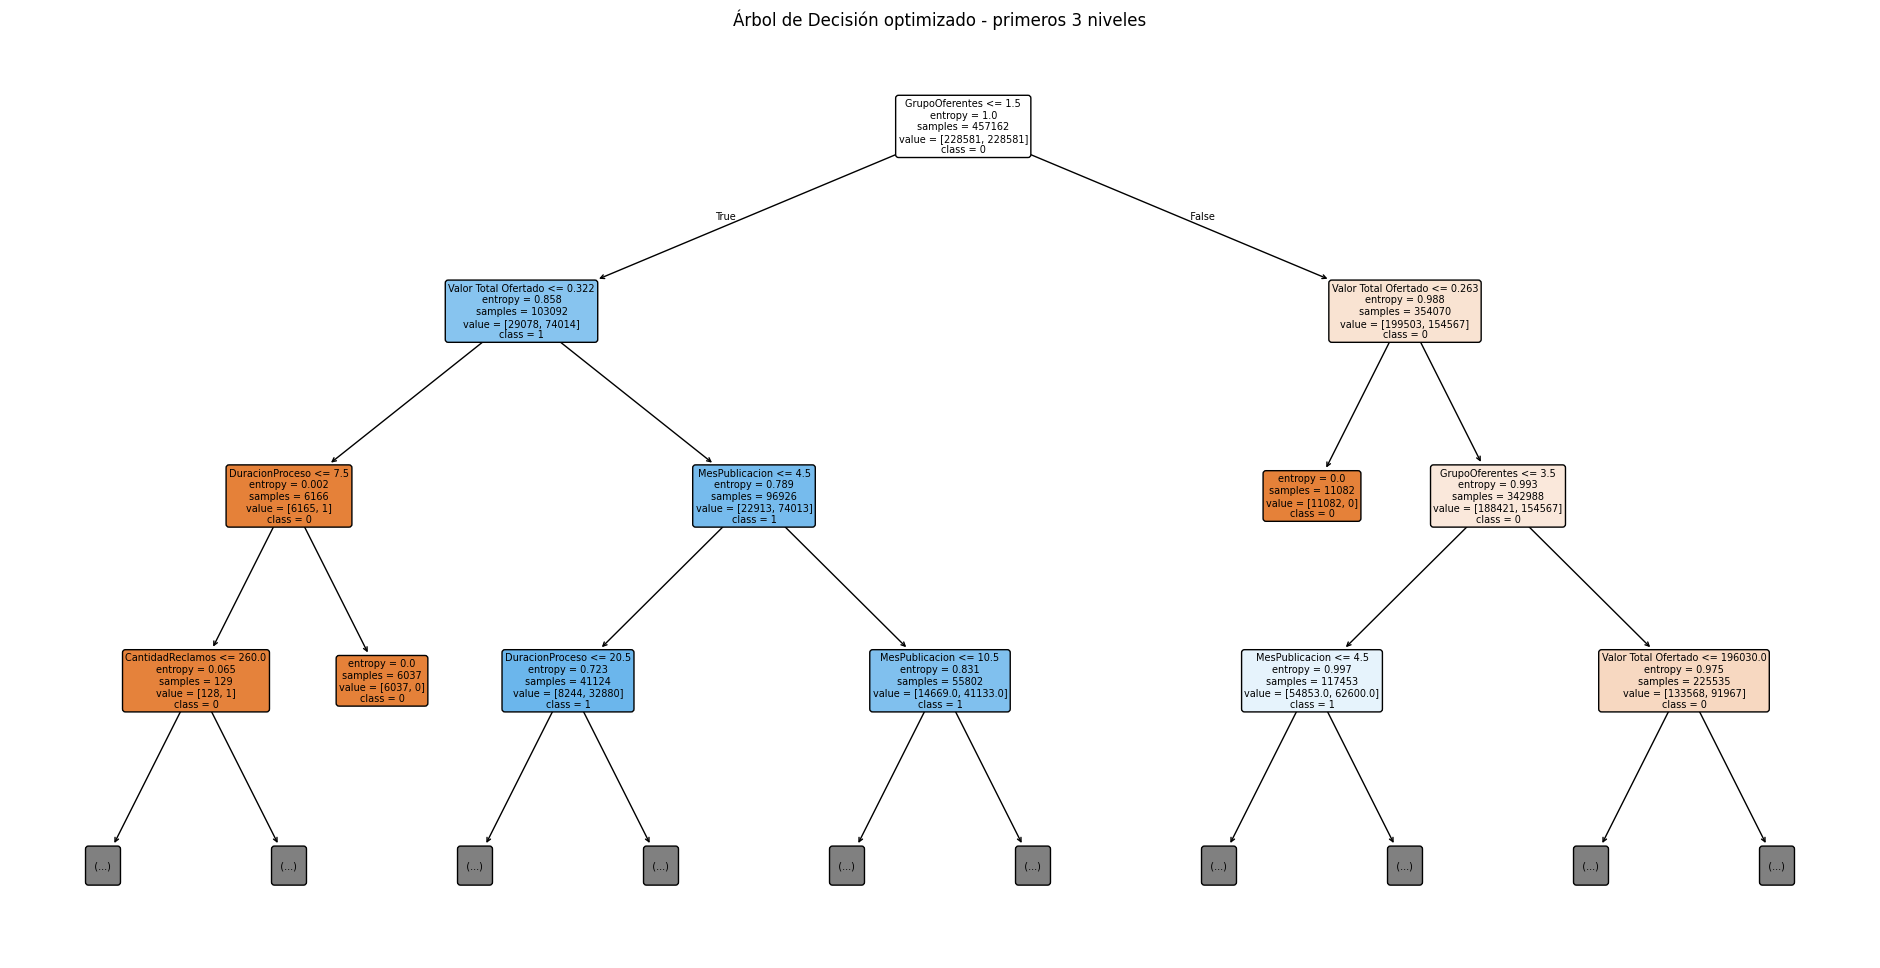

In [34]:
plt.figure(figsize=(24, 12))
plot_tree(
    tree_clf,
    feature_names=cols,
    class_names=["0", "1"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=7
)
plt.title("Árbol de Decisión optimizado - primeros 3 niveles")
plt.show()


## 12. Guardar modelo, umbral, hiperparámetros y columnas


In [35]:
artefacto_modelo = {
    "modelo": tree_clf,
    "umbral": float(mejor_umbral),
    "hiperparametros": mejores_params,
    "columnas": list(cols),
    "target": TARGET,
    "metricas_test": metricas_test.to_dict(orient="records")[0]
}

joblib.dump(
    artefacto_modelo,
    "arbol_decision_licitaciones_optimizado.joblib"
)

print("Guardado: arbol_decision_licitaciones_optimizado.joblib")


Guardado: arbol_decision_licitaciones_optimizado.joblib


## 13. Ejemplo de uso posterior


In [36]:
# Ejemplo (no ejecutar hasta disponer de X_nuevo):
# cargado = joblib.load("arbol_decision_licitaciones_optimizado.joblib")
# modelo = cargado["modelo"]
# umbral = cargado["umbral"]
# columnas = cargado["columnas"]
#
# X_nuevo = X_nuevo[columnas]
# proba = modelo.predict_proba(X_nuevo)[:, 1]
# pred = (proba >= umbral).astype(np.int8)
